# Core Concepts: Wavefronts and Optical Elements

We'll explore the `Wavefront` object and how optical elements transform wavefronts through amplitude and phase modifications. We'll propagate wavefronts in different regimes and build a simple optical system.

In [1]:
import hcipy
import numpy as np
import matplotlib.pyplot as plt


A `Wavefront` stores the complex electric field on a grid, combining both amplitude and phase information. Let's start by setting up a computational grid and defining a circular pupil aperture — these are the basic building blocks we'll use throughout.

In [2]:
# Create grid and aperture
pupil_diameter = 1
pupil_grid = hcipy.make_pupil_grid(128, pupil_diameter * 1.2)
aperture = hcipy.make_circular_aperture(1.0)(pupil_grid)


Now we'll build a planar wavefront from this aperture. Looking at the amplitude, phase, and intensity, we can see a perfect flat wavefront: the amplitude is uniform inside the pupil and zero outside, the phase is constant everywhere, and the intensity follows the same circular footprint as the amplitude.

Wavelength: 500 nm
Total power: 0.7840


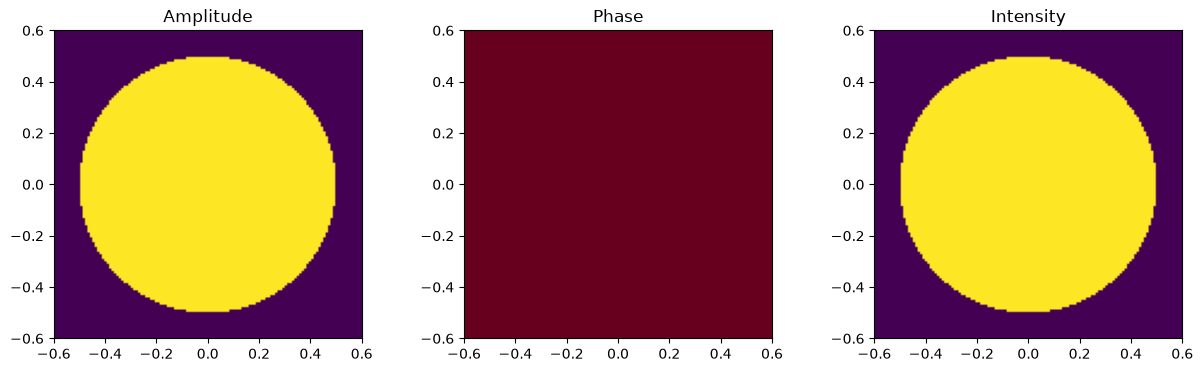

In [3]:
# Create wavefront and inspect properties
wavelength = 500e-9
wf = hcipy.Wavefront(aperture, wavelength)

print(f"Wavelength: {wf.wavelength*1e9:.0f} nm")
print(f"Total power: {wf.total_power:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
hcipy.imshow_field(wf.amplitude, ax=axes[0])
axes[0].set_title('Amplitude')
hcipy.imshow_field(wf.phase, cmap='RdBu', ax=axes[1])
axes[1].set_title('Phase')
hcipy.imshow_field(wf.intensity, ax=axes[2])
axes[2].set_title('Intensity')
plt.show()


Real optical systems introduce phase aberrations that distort the wavefront. We'll use Zernike polynomials to add two common aberrations: defocus and astigmatism. Defocus produces a parabolic phase map (bright center fading to dark edges), while astigmatism shows a distinctive saddle-shaped pattern with two orthogonal lobes.

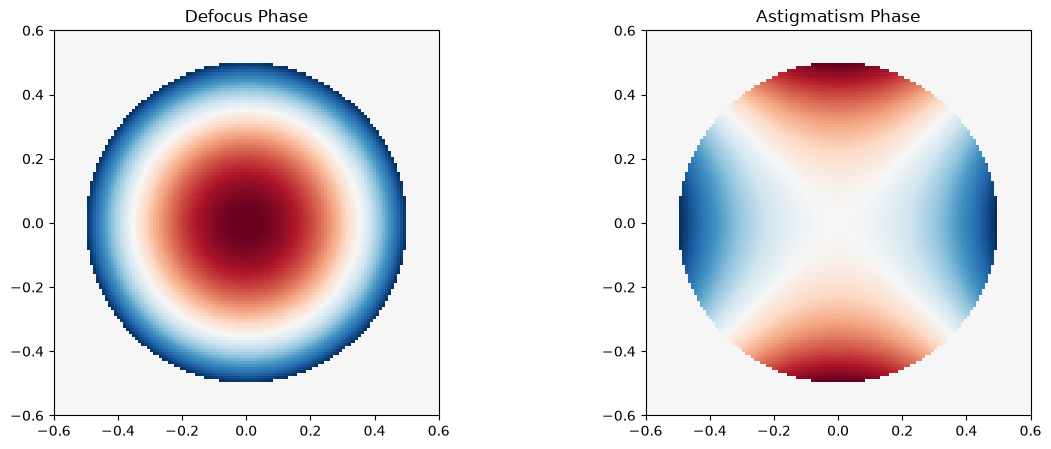

In [4]:
# Defocus
defocus_phase = hcipy.zernike(2, 0)(pupil_grid)
wf_defocus = hcipy.Wavefront(aperture * np.exp(1j * defocus_phase), wavelength)

# Astigmatism
astig_phase = hcipy.zernike(2, 2)(pupil_grid)
wf_astig = hcipy.Wavefront(aperture * np.exp(1j * astig_phase), wavelength)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hcipy.imshow_field(wf_defocus.phase, cmap='RdBu', ax=axes[0])
axes[0].set_title('Defocus Phase')
hcipy.imshow_field(wf_astig.phase, cmap='RdBu', ax=axes[1])
axes[1].set_title('Astigmatism Phase')
plt.show()


Next we'll propagate the planar wavefront to the focal plane using `FraunhoferPropagator`, which computes the far-field diffraction pattern — the point spread function (PSF). The resulting Airy pattern has a bright central core surrounded by concentric rings, with the first dark ring at a radius of about 1.22 λ/D from the center.

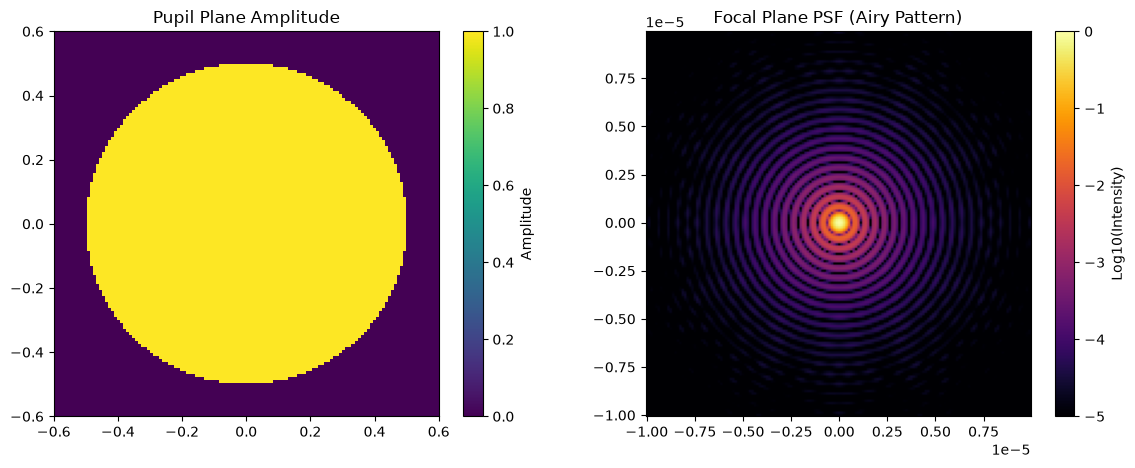

In [10]:
wf_in = hcipy.Wavefront(aperture, wavelength)

# Create focal grid and Fraunhofer propagator
focal_grid = hcipy.make_focal_grid(q=4, num_airy=20, spatial_resolution=wavelength / pupil_diameter)

fraunhofer = hcipy.FraunhoferPropagator(pupil_grid, focal_grid)
wf_focal = fraunhofer(wf_in)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hcipy.imshow_field(wf_in.amplitude, ax=axes[0])
axes[0].set_title('Pupil Plane Amplitude')

# Log-scale PSF
img = wf_focal.intensity / wf_focal.intensity.max()
hcipy.imshow_field(np.log10(img + 1e-20), cmap='inferno', vmin=-5, ax=axes[1])
axes[1].set_title('Focal Plane PSF (Airy Pattern)')
plt.colorbar(axes[0].images[0], ax=axes[0], label='Amplitude')
plt.colorbar(axes[1].images[0], ax=axes[1], label='Log10(Intensity)')
plt.show()


For shorter propagation distances, the Fraunhofer approximation breaks down, so we'll use `FresnelPropagator` instead. This accounts for the quadratic phase factor that accumulates during propagation. With a Fresnel number of about 200, we're firmly in the near-field regime where the intensity pattern still resembles the pupil shape with some edge diffraction effects.

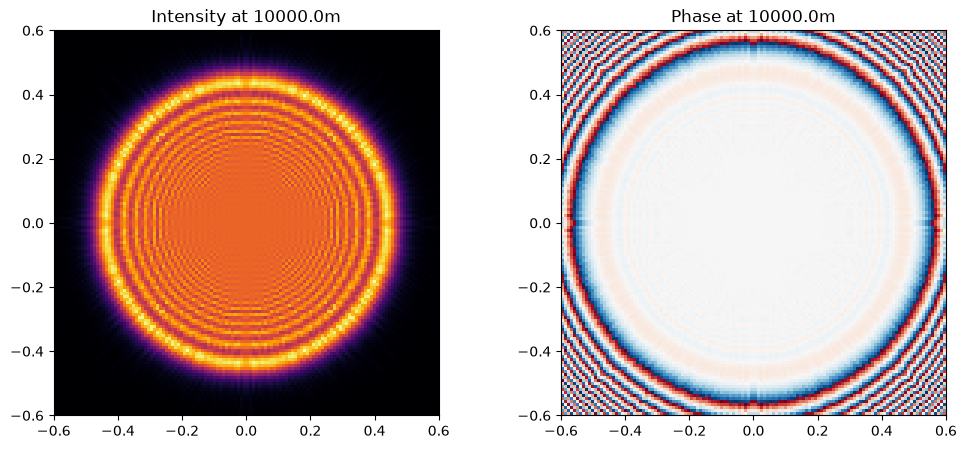

Fresnel number: 200.00


In [6]:
# Propagate with FresnelPropagator
distance = 10000.0  # meters
fresnel = hcipy.FresnelPropagator(pupil_grid, distance)
wf_near = fresnel(wf_in)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
hcipy.imshow_field(wf_near.intensity, cmap='inferno', ax=axes[0])
axes[0].set_title(f'Intensity at {distance}m')
hcipy.imshow_field(wf_near.phase, cmap='RdBu', ax=axes[1])
axes[1].set_title(f'Phase at {distance}m')
plt.show()

print(f"Fresnel number: {pupil_diameter**2 / (wavelength * distance):.2f}")


Let's add some aberrations to see how wavefront errors degrade image quality. We'll create a phase screen — a sinusoidal ripple modulated by a Gaussian envelope — and apply it to the wavefront.

In [7]:
# Create phase screen
phase_screen = 0.5 * np.sin(2 * np.pi * pupil_grid.x) * np.exp(-pupil_grid.as_('polar').r**2)

# Apply to wavefront
wf_aberrated = hcipy.Wavefront(wf_in.electric_field * np.exp(1j * phase_screen), wavelength)


Now we propagate both the ideal and aberrated wavefronts to the focal plane and compare their PSFs. The Strehl ratio compares the peak focal-plane intensity of the aberrated PSF to the ideal one — values near 1 mean diffraction-limited performance, while our value will be noticeably lower, reflecting the phase errors we introduced.

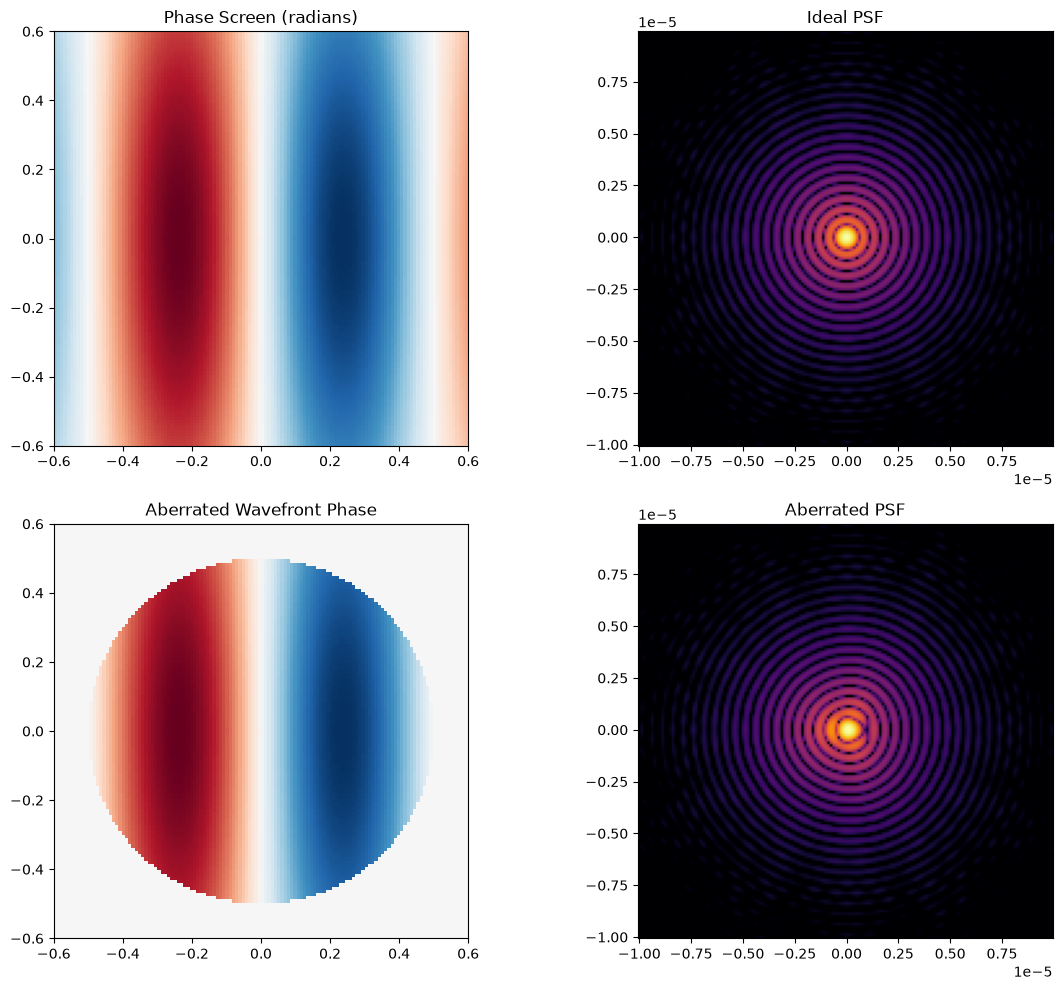

Strehl ratio: 0.9544


In [8]:
wf_focal_ideal = fraunhofer(wf_in)
wf_focal_aberrated = fraunhofer(wf_aberrated)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

hcipy.imshow_field(phase_screen, cmap='RdBu', ax=axes[0,0])
axes[0,0].set_title('Phase Screen (radians)')

hcipy.imshow_field(np.log10(wf_focal_ideal.intensity / wf_focal_ideal.intensity.max() + 1e-20), cmap='inferno', vmin=-5, ax=axes[0, 1])
axes[0,1].set_title('Ideal PSF')

hcipy.imshow_field(wf_aberrated.phase, cmap='RdBu', ax=axes[1,0])
axes[1,0].set_title('Aberrated Wavefront Phase')

hcipy.imshow_field(np.log10(wf_focal_aberrated.intensity / wf_focal_aberrated.intensity.max() + 1e-20), cmap='inferno', vmin=-5, ax=axes[1, 1])
axes[1,1].set_title('Aberrated PSF')

plt.tight_layout()
plt.show()

# Strehl ratio
strehl = wf_focal_aberrated.intensity.max() / wf_focal_ideal.intensity.max()
print(f"Strehl ratio: {strehl:.4f}")
